# GLD965 15m: next-bar five-period price MA

Forecast the next bar’s trailing five-period average price. Four of five prices are known at decision time. Compare against structural price persistence, not just conventional price-level R2. Z_return_lag5 remains a historical candidate predictor. Four outer time-series folds, thirty-bar embargo, separate inner selection and tuning blocks. Source code records all thresholds and search grids.

In [1]:
import sys
from pathlib import Path
repo=Path('/workspace/tidewatch_wiki') if Path('/workspace/tidewatch_wiki').exists() else next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'research/mts_gold').exists())
sys.path.insert(0,str(repo/'research/mts_gold/code'))
from model1_15m_priceMA import run,CONFIG,GRIDS
from IPython.display import display,Image
display(CONFIG)
display(GRIDS)
results=run()

{'target': 'Y(t+1) = mean(P[t-3],P[t-2],P[t-1],P[t],P[t+1]); five contiguous 15m closes',
 'target_scaling': 'fold-training mean/std; forecasts inverted to original THB quote units',
 'Z_return_lag5': 'one-bar log return five observed MTS bars ago / sigma at that historical bar; clipped [-5,5]',
 'outer_folds': 4,
 'embargo_context_bars': 30,
 'ewma_half_life': 30,
 'null_threshold': 0.2,
 'vif_threshold': 10,
 'varclus_top_per_cluster': 3,
 'permutation_top_max': 45,
 'seed': 42,
 'selection': 'inner training diagnostics; separate chronological selection and tuning blocks inside outer training',
 'source_lags': 'existing source lag fields shifted one additional MTS row: all X ends strictly before decision bar',
 'near_zero_band': 0.05}

{'Lasso': {'alpha': [0.001, 0.01, 0.1]},
 'ElasticNet': {'alpha': [0.001, 0.01, 0.1], 'l1_ratio': [0.25, 0.75]},
 'LightGBMRegressor': {'n_estimators': [100, 250],
  'learning_rate': [0.03, 0.07],
  'min_child_samples': [50, 150]}}

Fold 1 start


/workspace/tidewatch_wiki/research/mts_gold/code/model1_15m_priceMA.py:35: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  f['y_ma5']=ma.shift(-1).where(contiguous.shift(-1).fillna(False) & ma.notna())


Fold 1 complete, selected 45


Fold 2 start


... (2 outputs left out)

Fold 3 complete, selected 45


Fold 4 start


Fold 4 complete, selected 45


                 model  rows         RMSE          MAE        R2          MSE  skill_vs_structural  mse_improvement_ci_low  mse_improvement_ci_high  acceptance_ci_positive                                          bootstrap_method
            ElasticNet 32185  2290.326263  1462.182916  0.913737 5.245594e+06        -15273.398852           -5.743920e+06            -4.758429e+06                   False paired circular 30-observation blocks, stratified by fold
                 Lasso 32185  2326.586837  1504.637655  0.910984 5.413006e+06        -15760.877716           -5.911214e+06            -4.927823e+06                   False paired circular 30-observation blocks, stratified by fold
     LightGBMRegressor 32185  5117.155959  3427.826990  0.569389 2.618529e+07        -76246.696433           -2.941511e+07            -2.323679e+07                   False paired circular 30-observation blocks, stratified by fold
        MA_persistence 32185    40.394774    23.993469  0.999973 1.631738e+03   

In [2]:
display(results['waterfall'])
display(results['schedule'])
display(results['selected_features'])
display(results['summary'])
display(results['pairwise_comparison'])

,fold,stage,before,after,dropped,dropped_features
0,1,1 strictly lagged inputs,246,196,50,open;high;low;close;source_count;purity_pct;mt...
1,1,2 null >=20%,196,129,67,mts_xauusd_1d_close_lag30;mts_xauusd_1d_return...
2,1,3 zero variance,129,121,8,mts965_15m_elapsed_min_lag1;mts_xauusd_15m_ela...
3,1,4 VARCLUS top 3 per cluster,121,76,45,mts965_15m_close_lag1;mts965_15m_close_lag5;mt...
4,1,5 iterative VIF >10,76,46,30,mts_xauusd_15m_close_lag5;mts_xauusd_15m_close...
5,1,6 Lasso permutation top up to 45,46,45,1,wti_oil_1d_return_lag5
6,2,1 strictly lagged inputs,246,196,50,open;high;low;close;source_count;purity_pct;mt...
7,2,2 null >=20%,196,133,63,mts_xauusd_1d_close_lag30;mts_xauusd_1d_return...
8,2,3 zero variance,133,125,8,mts965_15m_elapsed_min_lag1;mts_xauusd_15m_ela...
9,2,4 VARCLUS top 3 per cluster,125,72,53,mts965_15m_close_lag30;mts9999_15m_close_lag1;...


,fold,train_rows,selection_fit_rows,permutation_rows,tuning_rows,test_rows,train_end,test_start,test_end,inner_seed,outer_seed,features
0,1,8007,4803,1579,1575,8044,2025-05-16 01:15:00+00:00,2025-05-16 09:15:00+00:00,2025-09-30 06:30:00+00:00,5.536554e-07,1.002572e-06,45
1,2,16053,9622,3196,3178,8029,2025-09-29 20:45:00+00:00,2025-09-30 07:00:00+00:00,2026-02-12 05:15:00+00:00,9.465522e-07,7.403088e-07,45
2,3,24087,14465,4785,4784,8062,2026-02-11 20:30:00+00:00,2026-02-12 05:45:00+00:00,2026-06-26 13:15:00+00:00,7.652692e-07,1.459727e-06,45
3,4,32145,19277,6402,6409,8050,2026-06-26 05:45:00+00:00,2026-06-26 13:45:00+00:00,2026-11-06 21:45:00+00:00,9.559899e-07,1.742002e-06,45


,fold,feature
0,1,mts_xauusd_15m_close_lag1
1,1,btcusdt_15m_close_lag30
2,1,own_return_variance15_lag1
3,1,us_yield_30y_1d_return_lag5
4,1,mts_xauusd_1d_close_lag5
...,...,...
175,4,us_yield_30y_1d_return_lag5
176,4,us_yield_3m_1d_return_lag1
177,4,usdthb_1d_return_lag1
178,4,vix_1d_elapsed_min_lag30


,model,rows,RMSE,MAE,R2,MSE,skill_vs_structural,mse_improvement_ci_low,mse_improvement_ci_high,acceptance_ci_positive,bootstrap_method
0,ElasticNet,32185,2290.326263,1462.182916,0.913737,5.245594e+06,-15273.398852,-5.743920e+06,-4.758429e+06,False,"paired circular 30-observation blocks, stratif..."
1,Lasso,32185,2326.586837,1504.637655,0.910984,5.413006e+06,-15760.877716,-5.911214e+06,-4.927823e+06,False,"paired circular 30-observation blocks, stratif..."
2,LightGBMRegressor,32185,5117.155959,3427.826990,0.569389,2.618529e+07,-76246.696433,-2.941511e+07,-2.323679e+07,False,"paired circular 30-observation blocks, stratif..."
3,MA_persistence,32185,40.394774,23.993469,0.999973,1.631738e+03,-3.751380,-1.608304e+03,-1.036355e+03,False,"paired circular 30-observation blocks, stratif..."
4,price_persistence,32185,71.204519,42.028659,0.999917,5.070083e+03,-13.763337,-5.846973e+03,-3.918007e+03,False,"paired circular 30-observation blocks, stratif..."
5,structural_persistence,32185,18.531701,11.088420,0.999994,3.434240e+02,0.000000,0.000000e+00,0.000000e+00,False,"paired circular 30-observation blocks, stratif..."
6,train_mean,32185,12453.925903,10870.557898,-1.550586,1.551003e+08,-451628.160592,-1.613587e+08,-1.490229e+08,False,"paired circular 30-observation blocks, stratif..."


,first,second,mse_improvement_ci_low,mse_improvement_ci_high,acceptance_ci_positive,bootstrap_method
0,Lasso,ElasticNet,-2.618416e+05,-9.064323e+04,False,"paired circular 30-observation blocks, stratif..."
1,Lasso,LightGBMRegressor,1.790128e+07,2.394397e+07,True,"paired circular 30-observation blocks, stratif..."
2,ElasticNet,LightGBMRegressor,1.808858e+07,2.410768e+07,True,"paired circular 30-observation blocks, stratif..."


,fold,model,partition,parameters,rows,RMSE,MAE,R2,MSE,skill_vs_structural
0,1,MA_persistence,validation,{},8044,15.097893,11.008603,0.999925,2.279464e+02,-3.355928
1,1,structural_persistence,validation,{},8044,7.233958,5.259945,0.999983,5.233015e+01,0.000000
2,1,price_persistence,validation,{},8044,27.248240,19.894257,0.999756,7.424666e+02,-13.188123
3,1,train_mean,validation,{},8044,4873.531412,4551.327900,-6.821362,2.375131e+07,-453873.273113
4,1,Lasso,validation,"{""alpha"": 0.01}",8044,450.940682,401.507093,0.933037,2.033475e+05,-3884.857430
5,1,Lasso,train,"{""alpha"": 0.01}",8007,326.235082,261.788782,0.988638,1.064293e+05,-1094.194316
6,1,ElasticNet,validation,"{""alpha"": 0.01, ""l1_ratio"": 0.25}",8044,422.490435,349.200279,0.941220,1.784982e+05,-3410.000555
7,1,ElasticNet,train,"{""alpha"": 0.01, ""l1_ratio"": 0.25}",8007,299.043611,239.569692,0.990453,8.942708e+04,-919.235355
8,1,LightGBMRegressor,validation,"{""learning_rate"": 0.07, ""min_child_samples"": 1...",8044,1578.423430,1275.004514,0.179569,2.491421e+06,-47608.658383
9,1,LightGBMRegressor,train,"{""learning_rate"": 0.07, ""min_child_samples"": 1...",8007,88.464571,65.502230,0.999165,7.825980e+03,-79.532023


,fold,model,parameters,tuning_mse_scaled
0,1,Lasso,"{""alpha"": 0.001}",0.380900
1,1,Lasso,"{""alpha"": 0.01}",0.379742
2,1,Lasso,"{""alpha"": 0.1}",0.763721
3,1,ElasticNet,"{""alpha"": 0.001, ""l1_ratio"": 0.25}",0.472851
4,1,ElasticNet,"{""alpha"": 0.001, ""l1_ratio"": 0.75}",0.402080
...,...,...,...,...
63,4,LightGBMRegressor,"{""learning_rate"": 0.03, ""min_child_samples"": 1...",6.397141
64,4,LightGBMRegressor,"{""learning_rate"": 0.07, ""min_child_samples"": 5...",6.713604
65,4,LightGBMRegressor,"{""learning_rate"": 0.07, ""min_child_samples"": 5...",6.620276
66,4,LightGBMRegressor,"{""learning_rate"": 0.07, ""min_child_samples"": 1...",6.937268


,feature,validation_rows,importance_mean,importance_std,importance_p05,importance_p95,positive_repeat_fraction,coefficient_zero,importance_definition,selected,fold
0,mts_xauusd_15m_close_lag1,1579,1.083212,0.167713,0.855120,1.369488,1.0,False,increase_in_validation_MSE_z,True,1
1,btcusdt_15m_close_lag30,1579,0.031971,0.004907,0.023339,0.038115,1.0,False,increase_in_validation_MSE_z,True,1
2,own_return_variance15_lag1,1579,0.015259,0.004885,0.005983,0.021430,1.0,False,increase_in_validation_MSE_z,True,1
3,us_yield_30y_1d_return_lag5,1579,0.010676,0.003793,0.006853,0.017231,1.0,False,increase_in_validation_MSE_z,True,1
4,mts_xauusd_1d_close_lag5,1579,0.004002,0.000838,0.002759,0.005256,1.0,False,increase_in_validation_MSE_z,True,1
...,...,...,...,...,...,...,...,...,...,...,...
202,us_yield_2y_1d_elapsed_min_lag30,6402,-0.008860,0.002167,-0.012056,-0.005833,0.0,False,increase_in_validation_MSE_z,False,4
203,us_yield_2y_1d_close_lag30,6402,-0.027347,0.002816,-0.031594,-0.023508,0.0,False,increase_in_validation_MSE_z,False,4
204,btcusdt_1d_return_lag30,6402,-0.028413,0.010047,-0.043609,-0.013286,0.0,False,increase_in_validation_MSE_z,False,4
205,us_yield_3m_1d_return_lag30,6402,-0.064866,0.018005,-0.098640,-0.045311,0.0,False,increase_in_validation_MSE_z,False,4


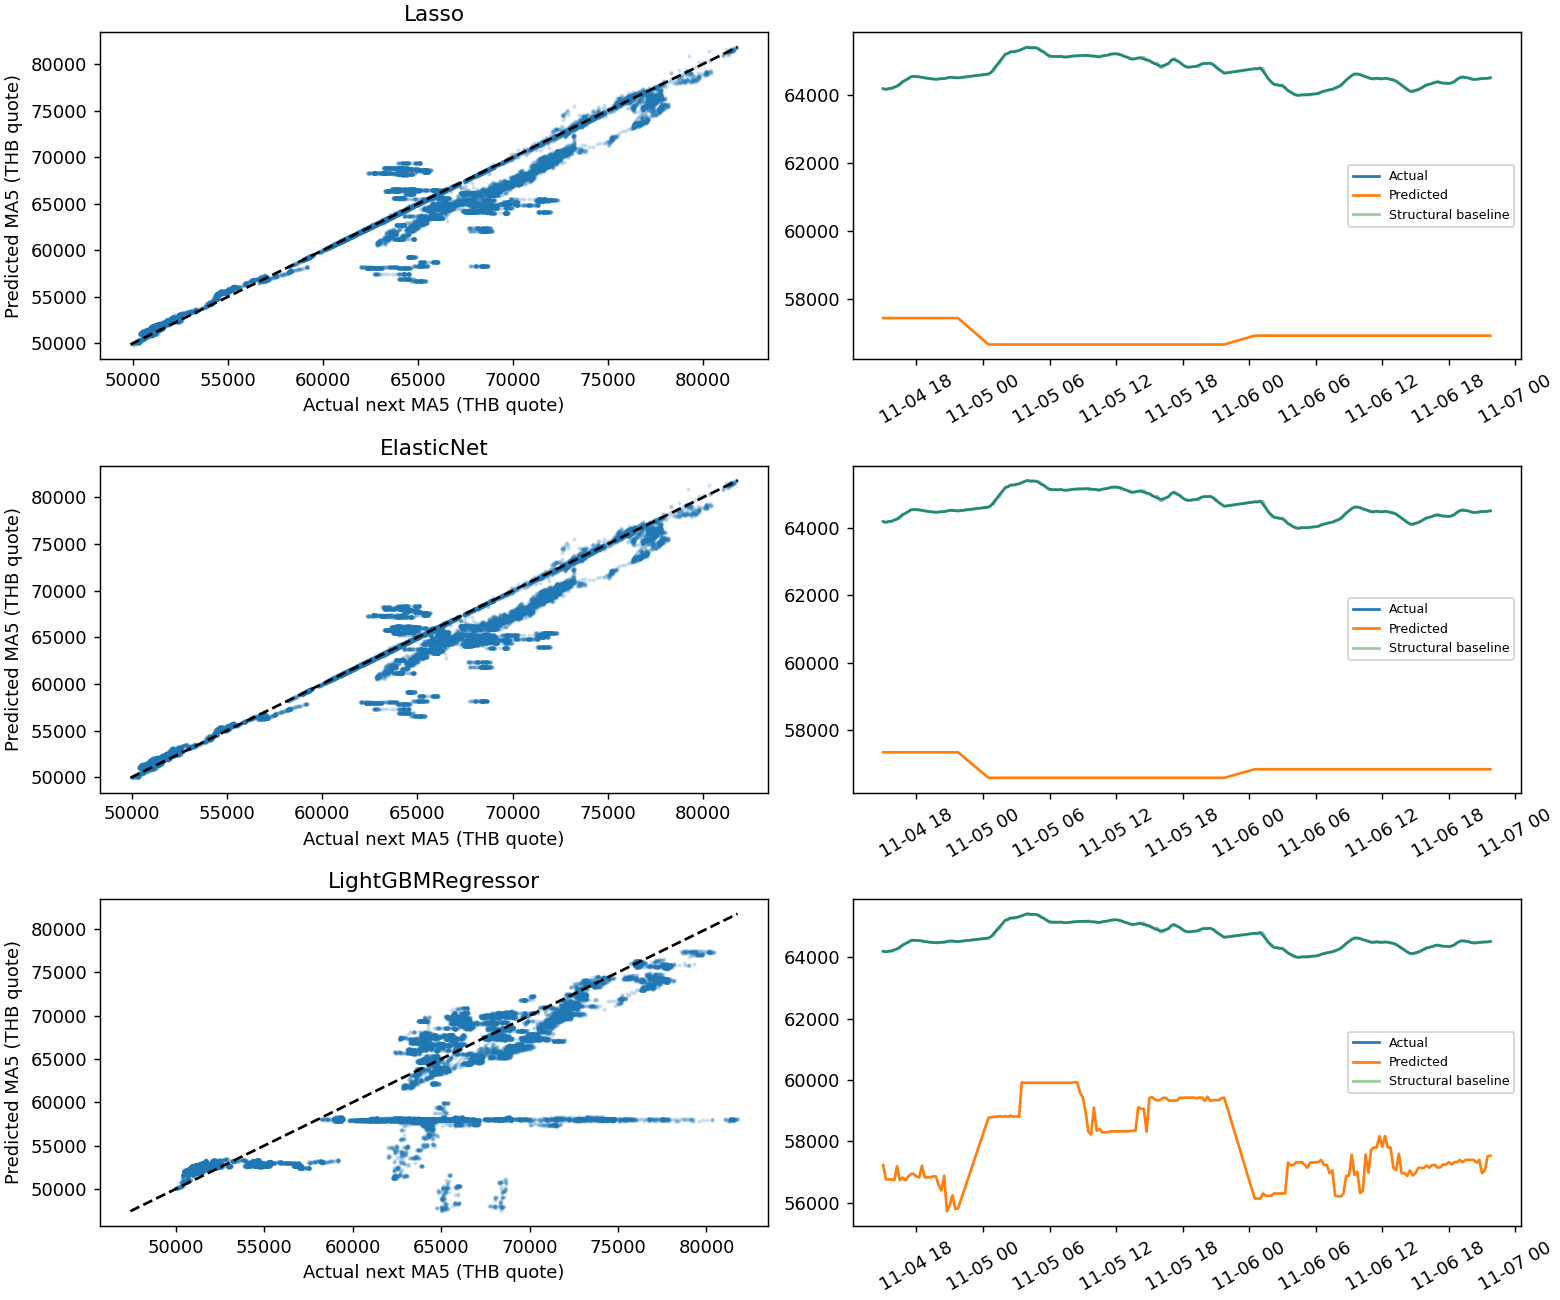

,decision_at,label_at,close,ma5_current,structural_persistence,y_ma5,y_hat,model,fold
0,2025-05-16 09:15:00+00:00,2025-05-16 09:30:00+00:00,50383.0,50366.0,50386.0,50396.0,50366.0,MA_persistence,1
1,2025-05-16 09:30:00+00:00,2025-05-16 09:45:00+00:00,50433.0,50396.0,50407.0,50398.8,50396.0,MA_persistence,1
2,2025-05-16 09:45:00+00:00,2025-05-16 10:00:00+00:00,50392.0,50398.8,50401.6,50407.6,50398.8,MA_persistence,1
3,2025-05-16 10:00:00+00:00,2025-05-16 10:15:00+00:00,50422.0,50407.6,50410.4,50398.2,50407.6,MA_persistence,1
4,2025-05-16 10:15:00+00:00,2025-05-16 10:30:00+00:00,50361.0,50398.2,50393.8,50392.6,50398.2,MA_persistence,1
5,2025-05-16 10:30:00+00:00,2025-05-16 10:45:00+00:00,50355.0,50392.6,50377.0,50359.4,50392.6,MA_persistence,1
6,2025-05-16 10:45:00+00:00,2025-05-16 11:00:00+00:00,50267.0,50359.4,50334.4,50294.0,50359.4,MA_persistence,1
7,2025-05-16 11:00:00+00:00,2025-05-16 11:15:00+00:00,50065.0,50294.0,50222.6,50207.2,50294.0,MA_persistence,1
8,2025-05-16 11:15:00+00:00,2025-05-16 11:30:00+00:00,49988.0,50207.2,50132.6,50134.0,50207.2,MA_persistence,1
9,2025-05-16 11:30:00+00:00,2025-05-16 11:45:00+00:00,49995.0,50134.0,50062.0,50066.0,50134.0,MA_persistence,1


In [3]:
display(results['fold_metrics'])
display(results['tuning'])
display(results['permutation'])
display(Image(filename=str(repo/'research/mts_gold/training_artifacts/_training_baseline/model1_15m_priceMA/predicted_actual.png')))
display(results['predictions'].head(20))